In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from scipy import stats
from statsmodels.stats.multitest import multipletests

In [2]:
PROJECT_DIR = Path("/Users/hyuna/OpenNeuro/ds007116")
PHENO_DIR = PROJECT_DIR / "phenotype"
DERIVED_DIR = PROJECT_DIR / "derived"

RESULTS_DIR = PROJECT_DIR / "results" / "summary_tables"
FIGURE_DIR = PROJECT_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CLUSTER_FILE = DERIVED_DIR / "gmm_cluster_assignments_k5.csv"

print("Cluster file exists:", CLUSTER_FILE.exists())

Cluster file exists: True


In [3]:
clusters = pd.read_csv(CLUSTER_FILE)

print("Shape:", clusters.shape)
display(clusters.head())

print("\nCluster sizes:")
print(
    clusters["cluster"]
    .value_counts()
    .sort_index()
)

Shape: (92, 4)


,participant_id,session_id,cluster,prob
0,sub-138950,ses-1,4,0.986002
1,sub-19861,ses-1,1,0.997255
2,sub-20125,ses-1,1,0.983757
3,sub-20139,ses-1,1,0.999997
4,sub-20141,ses-1,1,1.000000



Cluster sizes:
cluster
0     6
1    41
2     9
3     7
4    29
Name: count, dtype: int64


In [4]:
assert len(clusters) == 92
assert clusters["participant_id"].nunique() == 92
assert clusters["session_id"].eq("ses-1").all()

In [10]:
PARTICIPANTS_FILE = PROJECT_DIR / "participants.tsv"

participants = pd.read_csv(
    PARTICIPANTS_FILE,
    sep="\t"
)

print("Participants shape:", participants.shape)

print("\nStudy group distribution:")
print(
    participants["study_group"]
    .value_counts(dropna=False)
)

display(
    participants[
        ["participant_id", "study_group"]
    ].head()
)

Participants shape: (132, 17)

Study group distribution:
study_group
PRO/CHR    69
TD/NC      36
ADHD       27
Name: count, dtype: int64


,participant_id,study_group
0,sub-19861,ADHD
1,sub-20124,TD/NC
2,sub-20125,PRO/CHR
3,sub-20139,TD/NC
4,sub-20141,TD/NC


In [11]:
diagnostic_df = clusters.merge(
    participants[
        ["participant_id", "study_group"]
    ],
    on="participant_id",
    how="left",
    validate="many_to_one"
)

print("Merged shape:", diagnostic_df.shape)
print(
    "Unique participants:",
    diagnostic_df["participant_id"].nunique()
)

print(
    "Missing study_group:",
    diagnostic_df["study_group"].isna().sum()
)

print("\nCluster sizes:")
print(
    diagnostic_df["cluster"]
    .value_counts()
    .sort_index()
)

print("\nStudy groups:")
print(
    diagnostic_df["study_group"]
    .value_counts(dropna=False)
)

Merged shape: (92, 5)
Unique participants: 92
Missing study_group: 0

Cluster sizes:
cluster
0     6
1    41
2     9
3     7
4    29
Name: count, dtype: int64

Study groups:
study_group
PRO/CHR    51
TD/NC      22
ADHD       19
Name: count, dtype: int64


In [12]:
diagnostic_table = pd.crosstab(
    diagnostic_df["cluster"],
    diagnostic_df["study_group"]
)

display(diagnostic_table)

study_group,ADHD,PRO/CHR,TD/NC
cluster,,,
0,0,4,2
1,5,25,11
2,3,6,0
3,3,3,1
4,8,13,8


In [13]:
diagnostic_prop = pd.crosstab(
    diagnostic_df["cluster"],
    diagnostic_df["study_group"],
    normalize="index"
) * 100

display(
    diagnostic_prop.round(1)
)

study_group,ADHD,PRO/CHR,TD/NC
cluster,,,
0,0.0,66.7,33.3
1,12.2,61.0,26.8
2,33.3,66.7,0.0
3,42.9,42.9,14.3
4,27.6,44.8,27.6


In [14]:
chi2, p_chi, dof, expected = stats.chi2_contingency(
    diagnostic_table
)

n = diagnostic_table.to_numpy().sum()
r, c = diagnostic_table.shape

cramers_v = np.sqrt(
    chi2 /
    (n * min(r - 1, c - 1))
)

print(f"Chi-square = {chi2:.3f}")
print(f"df = {dof}")
print(f"p = {p_chi:.4f}")
print(f"Cramer's V = {cramers_v:.3f}")

Chi-square = 10.019
df = 8
p = 0.2637
Cramer's V = 0.233


In [15]:
expected_df = pd.DataFrame(
    expected,
    index=diagnostic_table.index,
    columns=diagnostic_table.columns
)

display(
    expected_df.round(2)
)

n_small = (expected < 5).sum()
pct_small = (expected < 5).mean() * 100

print(
    f"Expected cells < 5: "
    f"{n_small}/{expected.size} "
    f"({pct_small:.1f}%)"
)

study_group,ADHD,PRO/CHR,TD/NC
cluster,,,
0,1.24,3.33,1.43
1,8.47,22.73,9.80
2,1.86,4.99,2.15
3,1.45,3.88,1.67
4,5.99,16.08,6.93


Expected cells < 5: 9/15 (60.0%)


In [16]:
rng = np.random.default_rng(42)

n_perm = 10000
observed_chi2 = chi2

cluster_values = diagnostic_df["cluster"].to_numpy()
group_values = diagnostic_df["study_group"].to_numpy()

permuted_chi2 = np.empty(n_perm)

for i in range(n_perm):

    shuffled_group = rng.permutation(
        group_values
    )

    perm_table = pd.crosstab(
        cluster_values,
        shuffled_group
    )

    perm_table = perm_table.reindex(
        index=diagnostic_table.index,
        columns=diagnostic_table.columns,
        fill_value=0
    )

    perm_chi2, _, _, _ = stats.chi2_contingency(
        perm_table
    )

    permuted_chi2[i] = perm_chi2


p_perm = (
    np.sum(
        permuted_chi2 >= observed_chi2
    ) + 1
) / (n_perm + 1)


print(
    f"Observed chi-square = "
    f"{observed_chi2:.3f}"
)

print(
    f"Asymptotic p = "
    f"{p_chi:.4f}"
)

print(
    f"Permutation p = "
    f"{p_perm:.4f}"
)

print(
    f"Cramer's V = "
    f"{cramers_v:.3f}"
)

Observed chi-square = 10.019
Asymptotic p = 0.2637
Permutation p = 0.2702
Cramer's V = 0.233


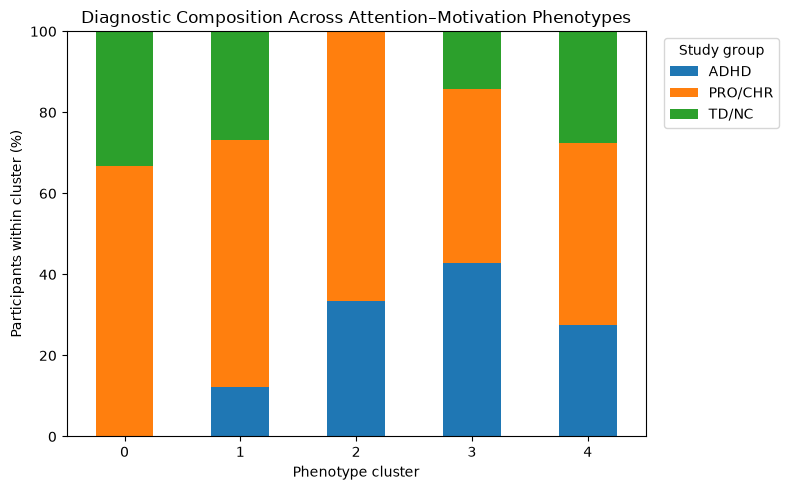

In [17]:
diagnostic_prop.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.xlabel("Phenotype cluster")
plt.ylabel("Participants within cluster (%)")

plt.title(
    "Diagnostic Composition Across "
    "Attention–Motivation Phenotypes"
)

plt.legend(
    title="Study group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "diagnostic_distribution_k5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
diagnostic_table.to_csv(
    RESULTS_DIR / "diagnostic_counts_k5.csv"
)

diagnostic_prop.to_csv(
    RESULTS_DIR / "diagnostic_proportions_k5.csv"
)

diagnostic_stats = pd.DataFrame({
    "chi_square": [chi2],
    "df": [dof],
    "p_asymptotic": [p_chi],
    "p_permutation": [p_perm],
    "cramers_v": [cramers_v],
    "expected_cells_below_5": [(expected < 5).sum()],
    "expected_cells_total": [expected.size],
    "percent_expected_below_5": [(expected < 5).mean() * 100]
})

diagnostic_stats.to_csv(
    RESULTS_DIR / "diagnostic_mapping_statistics_k5.csv",
    index=False
)

In [ ]:
### Diagnostic mapping summary

Phenotype membership was not significantly associated with
predefined study-group membership, χ²(8) = 10.02, p = .264,
Cramér's V = .233. Because 60% of expected cell counts were
below five, a permutation-based chi-square test was additionally
performed and yielded the same conclusion (p = .270).

Diagnostic groups were distributed across the five phenotypes,
indicating that the data-driven phenotype solution did not simply
reproduce the predefined ADHD, PRO/CHR, and TD/NC group
classification. This finding is interpreted descriptively rather
than as definitive evidence of transdiagnostic validity.

In [19]:
CLINICAL_KEYWORDS = [
    "bdi",
    "panas",
    "ari",
    "als",
    "asrm",
    "ppa",
    "stai",
    "maps",
    "rpas",
    "rsas"
]

clinical_files = []

for file in PHENO_DIR.glob("*.tsv"):

    name_lower = file.name.lower()

    if any(
        keyword in name_lower
        for keyword in CLINICAL_KEYWORDS
    ):
        clinical_files.append(file)

for file in clinical_files:

    temp = pd.read_csv(
        file,
        sep="\t",
        nrows=3
    )

    print("\n" + "=" * 70)
    print(file.name)
    print(temp.columns.tolist())


post_scan_stai_state.tsv
['participant_id', 'session_id', 'stai_q_01', 'stai_q_02', 'stai_q_03', 'stai_q_04', 'stai_q_05', 'stai_q_06', 'stai_q_07', 'stai_q_08', 'stai_q_09', 'stai_q_10', 'stai_q_11', 'stai_q_12', 'stai_q_13', 'stai_q_14', 'stai_q_15', 'stai_q_16', 'stai_q_17', 'stai_q_18', 'stai_q_19', 'stai_q_20', 'stai_state_complete', 'post_scan_STAI_state_total_score']

rsas.tsv
['participant_id', 'session_id', 'soc_anhed_1', 'soc_anhed_2', 'soc_anhed_3', 'soc_anhed_4', 'soc_anhed_5', 'soc_anhed_6', 'soc_anhed_7', 'soc_anhed_8', 'soc_anhed_9', 'soc_anhed_10', 'soc_anhed_11', 'soc_anhed_12', 'soc_anhed_13', 'soc_anhed_14', 'soc_anhed_15', 'revised_social_anhedonia_scale_rsas_complete', 'rsas_total_score', 'rsas_average_score']

ari.tsv
['participant_id', 'session_id', 'ari_1', 'ari_2', 'ari_3', 'ari_4', 'ari_5', 'ari_6', 'ari_7', 'ari_proband_complete', 'ari_total_score', 'ari_avg']

pre_scan_stai.tsv
['participant_id', 'session_id', 'stai_q_01', 'stai_q_02', 'stai_q_03', 'stai_q_

In [20]:
CLINICAL_OUTCOMES = {
    "BDI": (
        "bdi_1a_ms_child.tsv",
        "bdi_1a_ms_child_total_score"
    ),
    "PANAS Positive": (
        "panas.tsv",
        "panas_sum_pos"
    ),
    "PANAS Negative": (
        "panas.tsv",
        "panas_sum_neg"
    ),
    "ARI": (
        "ari.tsv",
        "ari_total_score"
    ),
    "ALS": (
        "als-18.tsv",
        "als_total_score"
    ),
    "ASRM": (
        "asrm.tsv",
        "asrm_total_score"
    ),
    "PPA": (
        "ppa.tsv",
        "ppa_total_score"
    ),
    "Pre-scan STAI State": (
        "pre_scan_stai.tsv",
        "pre_scan_STAI_state_total_score"
    ),
    "Pre-scan STAI Trait": (
        "pre_scan_stai.tsv",
        "pre_scan_STAI_trait_total_score"
    ),
    "Post-scan STAI State": (
        "post_scan_stai_state.tsv",
        "post_scan_STAI_state_total_score"
    ),
    "MAPS": (
        "mapssr.tsv",
        "mapssr_total_score"
    ),
    "RPAS": (
        "rpas.tsv",
        "rpas_total_score"
    ),
    "RSAS": (
        "rsas.tsv",
        "rsas_total_score"
    ),
}

print("Number of clinical outcomes:", len(CLINICAL_OUTCOMES))

Number of clinical outcomes: 13


In [21]:
clinical_data = {}

for name, (filename, outcome) in CLINICAL_OUTCOMES.items():

    file = PHENO_DIR / filename

    temp = pd.read_csv(
        file,
        sep="\t"
    )

    # Baseline only
    temp = temp[
        temp["session_id"] == "ses-1"
    ].copy()

    # Keep only necessary columns
    temp = temp[
        ["participant_id", "session_id", outcome]
    ]

    # Merge with final k=5 phenotype assignments
    merged = clusters.merge(
        temp,
        on=["participant_id", "session_id"],
        how="left",
        validate="one_to_one"
    )

    clinical_data[name] = {
        "outcome": outcome,
        "data": merged
    }

    print(
        f"{name:25s} "
        f"N = {merged[outcome].notna().sum()}"
    )

BDI                       N = 90
PANAS Positive            N = 55
PANAS Negative            N = 56
ARI                       N = 92
ALS                       N = 87
ASRM                      N = 92
PPA                       N = 55
Pre-scan STAI State       N = 84
Pre-scan STAI Trait       N = 80
Post-scan STAI State      N = 80
MAPS                      N = 83
RPAS                      N = 90
RSAS                      N = 80


In [22]:
descriptive_tables = {}

for name, info in clinical_data.items():

    outcome = info["outcome"]
    temp = info["data"]

    desc = (
        temp
        .dropna(subset=[outcome])
        .groupby("cluster")[outcome]
        .agg(
            N="count",
            Mean="mean",
            SD="std",
            Median="median"
        )
    )

    descriptive_tables[name] = desc

    print("\n" + "=" * 70)
    print(name)
    display(desc.round(2))


BDI


,N,Mean,SD,Median
cluster,,,,
0,6,5.50,4.23,3.5
1,40,6.82,6.31,6.0
2,9,9.89,9.47,7.0
3,7,11.00,10.89,8.0
4,28,4.04,3.82,4.0



PANAS Positive


,N,Mean,SD,Median
cluster,,,,
0,5,14.60,2.79,16.0
1,23,17.57,2.87,18.0
2,7,16.00,6.86,14.0
3,3,12.33,3.51,12.0
4,17,20.65,4.01,21.0



PANAS Negative


,N,Mean,SD,Median
cluster,,,,
0,5,7.60,1.95,9.0
1,22,10.55,3.19,10.5
2,7,11.14,5.21,10.0
3,5,9.00,4.30,8.0
4,17,7.76,2.19,7.0


... (16 outputs left out)


RPAS


,N,Mean,SD,Median
cluster,,,,
0,6,6.17,3.92,6.0
1,40,5.25,2.56,5.0
2,9,4.89,3.02,4.0
3,7,6.86,3.18,5.0
4,28,3.39,2.23,3.5



RSAS


,N,Mean,SD,Median
cluster,,,,
0,6,2.50,2.26,2.0
1,35,3.71,3.14,3.0
2,9,3.44,1.42,4.0
3,7,4.29,2.87,5.0
4,23,2.30,2.34,2.0


In [23]:
clinical_results = []

for name, info in clinical_data.items():

    outcome = info["outcome"]

    temp = (
        info["data"]
        .dropna(subset=[outcome])
        .copy()
    )

    groups = [
        group[outcome].to_numpy()
        for _, group in temp.groupby("cluster")
    ]

    # Check that all five clusters are represented
    if len(groups) != 5:
        print(
            f"WARNING: {name} has only "
            f"{len(groups)} represented clusters"
        )
        continue

    # ANOVA
    F, p_anova = stats.f_oneway(*groups)

    # Kruskal-Wallis
    H, p_kw = stats.kruskal(*groups)

    # Eta squared
    grand_mean = temp[outcome].mean()

    ss_between = sum(
        len(group) *
        (group[outcome].mean() - grand_mean) ** 2
        for _, group in temp.groupby("cluster")
    )

    ss_total = (
        (temp[outcome] - grand_mean) ** 2
    ).sum()

    eta2 = ss_between / ss_total

    # Epsilon squared
    n = len(temp)
    k = temp["cluster"].nunique()

    epsilon2 = (
        (H - k + 1) /
        (n - k)
    )

    clinical_results.append({
        "outcome": name,
        "N": n,
        "F": F,
        "p_anova": p_anova,
        "eta_squared": eta2,
        "H": H,
        "p_kw": p_kw,
        "epsilon_squared": epsilon2
    })

clinical_results = pd.DataFrame(
    clinical_results
)

display(
    clinical_results.round(4)
)

,outcome,N,F,p_anova,eta_squared,H,p_kw,epsilon_squared
0,BDI,90,2.6101,0.0411,0.1094,5.9947,0.1995,0.0235
1,PANAS Positive,55,4.8644,0.0022,0.2801,14.8720,0.0050,0.2174
2,PANAS Negative,56,2.6449,0.0440,0.1718,8.5767,0.0726,0.0897
3,ARI,92,2.9426,0.0248,0.1192,10.9447,0.0272,0.0798
4,ALS,87,2.6601,0.0384,0.1149,8.8412,0.0652,0.0590
5,ASRM,92,1.0567,0.3829,0.0463,3.6568,0.4544,-0.0039
6,PPA,55,1.0465,0.3927,0.0773,3.4572,0.4844,-0.0109
7,Pre-scan STAI State,84,4.1248,0.0044,0.1728,11.4774,0.0217,0.0947
8,Pre-scan STAI Trait,80,6.1978,0.0002,0.2484,21.2444,0.0003,0.2299
9,Post-scan STAI State,80,2.0297,0.0988,0.0977,10.0526,0.0396,0.0807


In [24]:
clinical_results["p_anova_fdr"] = multipletests(
    clinical_results["p_anova"],
    method="fdr_bh"
)[1]

clinical_results["p_kw_fdr"] = multipletests(
    clinical_results["p_kw"],
    method="fdr_bh"
)[1]

In [25]:
clinical_results = (
    clinical_results
    .sort_values(
        "p_kw_fdr"
    )
    .reset_index(drop=True)
)

display(
    clinical_results[
        [
            "outcome",
            "N",
            "F",
            "p_anova",
            "p_anova_fdr",
            "eta_squared",
            "H",
            "p_kw",
            "p_kw_fdr",
            "epsilon_squared"
        ]
    ].round(4)
)

,outcome,N,F,p_anova,p_anova_fdr,eta_squared,H,p_kw,p_kw_fdr,epsilon_squared
0,MAPS,83,13.9105,0.0000,0.0000,0.4164,22.8152,0.0001,0.0018,0.2412
1,Pre-scan STAI Trait,80,6.1978,0.0002,0.0015,0.2484,21.2444,0.0003,0.0018,0.2299
2,PANAS Positive,55,4.8644,0.0022,0.0094,0.2801,14.8720,0.0050,0.0216,0.2174
3,RPAS,90,3.6928,0.0080,0.0209,0.1480,12.3222,0.0151,0.0491,0.0979
4,Pre-scan STAI State,84,4.1248,0.0044,0.0142,0.1728,11.4774,0.0217,0.0564,0.0947
5,ARI,92,2.9426,0.0248,0.0537,0.1192,10.9447,0.0272,0.0589,0.0798
6,Post-scan STAI State,80,2.0297,0.0988,0.1284,0.0977,10.0526,0.0396,0.0735,0.0807
7,PANAS Negative,56,2.6449,0.0440,0.0635,0.1718,8.5767,0.0726,0.1049,0.0897
8,ALS,87,2.6601,0.0384,0.0635,0.1149,8.8412,0.0652,0.1049,0.0590
9,BDI,90,2.6101,0.0411,0.0635,0.1094,5.9947,0.1995,0.2594,0.0235


In [26]:
clinical_results.to_csv(
    RESULTS_DIR /
    "clinical_characterization_k5.csv",
    index=False
)

In [27]:
all_descriptives = []

for name, desc in descriptive_tables.items():

    temp = (
        desc
        .reset_index()
        .copy()
    )

    temp.insert(
        0,
        "outcome",
        name
    )

    all_descriptives.append(temp)

clinical_descriptives = pd.concat(
    all_descriptives,
    ignore_index=True
)

clinical_descriptives.to_csv(
    RESULTS_DIR /
    "clinical_descriptives_k5.csv",
    index=False
)

display(
    clinical_descriptives.head(10)
)

,outcome,cluster,N,Mean,SD,Median
0,BDI,0,6,5.500000,4.230839,3.5
1,BDI,1,40,6.825000,6.307860,6.0
2,BDI,2,9,9.888889,9.466315,7.0
3,BDI,3,7,11.000000,10.893423,8.0
4,BDI,4,28,4.035714,3.815001,4.0
5,PANAS Positive,0,5,14.600000,2.792848,16.0
6,PANAS Positive,1,23,17.565217,2.873485,18.0
7,PANAS Positive,2,7,16.000000,6.855655,14.0
8,PANAS Positive,3,3,12.333333,3.511885,12.0
9,PANAS Positive,4,17,20.647059,4.014679,21.0


In [28]:
significant_clinical = clinical_results[
    (clinical_results["p_anova_fdr"] < .05) |
    (clinical_results["p_kw_fdr"] < .05)
].copy()

print(
    "FDR-significant clinical outcomes:",
    len(significant_clinical)
)

display(
    significant_clinical[
        [
            "outcome",
            "N",
            "p_anova_fdr",
            "eta_squared",
            "p_kw_fdr",
            "epsilon_squared"
        ]
    ].round(4)
)

FDR-significant clinical outcomes: 5


,outcome,N,p_anova_fdr,eta_squared,p_kw_fdr,epsilon_squared
0,MAPS,83,0.0000,0.4164,0.0018,0.2412
1,Pre-scan STAI Trait,80,0.0015,0.2484,0.0018,0.2299
2,PANAS Positive,55,0.0094,0.2801,0.0216,0.2174
3,RPAS,90,0.0209,0.1480,0.0491,0.0979
4,Pre-scan STAI State,84,0.0142,0.1728,0.0564,0.0947


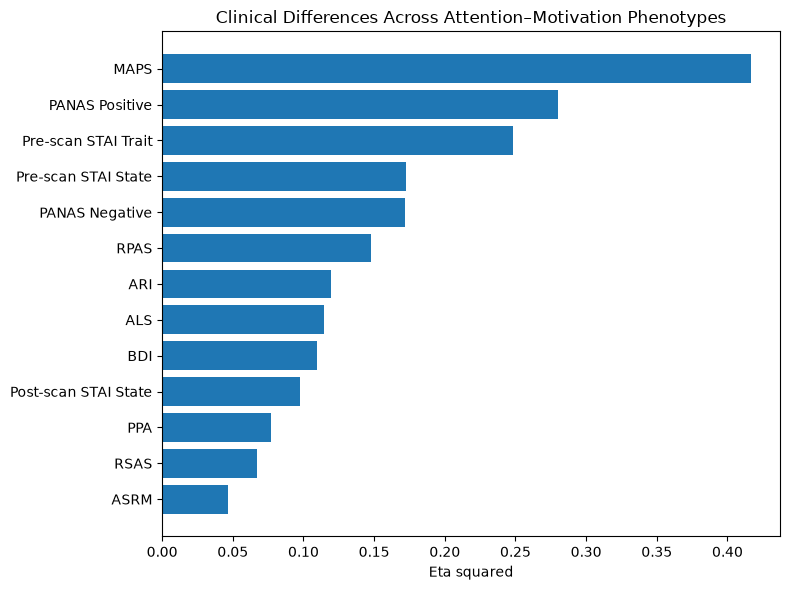

In [29]:
plot_results = (
    clinical_results
    .sort_values(
        "eta_squared",
        ascending=True
    )
)

plt.figure(figsize=(8, 6))

plt.barh(
    plot_results["outcome"],
    plot_results["eta_squared"]
)

plt.xlabel("Eta squared")
plt.ylabel("")
plt.title(
    "Clinical Differences Across "
    "Attention–Motivation Phenotypes"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR /
    "clinical_effect_sizes_k5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
KEY_OUTCOMES = [
    "MAPS",
    "Pre-scan STAI Trait",
    "PANAS Positive",
    "RPAS",
    "Pre-scan STAI State"
]

key_descriptives = clinical_descriptives[
    clinical_descriptives["outcome"].isin(KEY_OUTCOMES)
].copy()

display(
    key_descriptives
    .sort_values(["outcome", "cluster"])
    .round(2)
)

,outcome,cluster,N,Mean,SD,Median
50,MAPS,0,6,37.67,5.13,36.5
51,MAPS,1,37,36.08,9.61,39.0
52,MAPS,2,8,45.88,10.58,47.0
53,MAPS,3,7,13.29,13.96,11.0
54,MAPS,4,25,43.52,10.21,43.0
5,PANAS Positive,0,5,14.60,2.79,16.0
6,PANAS Positive,1,23,17.57,2.87,18.0
7,PANAS Positive,2,7,16.00,6.86,14.0
8,PANAS Positive,3,3,12.33,3.51,12.0
9,PANAS Positive,4,17,20.65,4.01,21.0


In [31]:
for name in KEY_OUTCOMES:

    info = clinical_data[name]
    outcome = info["outcome"]
    temp = info["data"]

    print(f"\n=== {name} ===")

    qc = (
        temp
        .groupby("cluster")[outcome]
        .agg(
            available="count",
            total="size"
        )
    )

    qc["missing"] = (
        qc["total"] - qc["available"]
    )

    qc["available_pct"] = (
        qc["available"] /
        qc["total"] * 100
    )

    display(qc.round(1))


=== MAPS ===


,available,total,missing,available_pct
cluster,,,,
0,6,6,0,100.0
1,37,41,4,90.2
2,8,9,1,88.9
3,7,7,0,100.0
4,25,29,4,86.2



=== Pre-scan STAI Trait ===


,available,total,missing,available_pct
cluster,,,,
0,6,6,0,100.0
1,35,41,6,85.4
2,6,9,3,66.7
3,6,7,1,85.7
4,27,29,2,93.1



=== PANAS Positive ===


,available,total,missing,available_pct
cluster,,,,
0,5,6,1,83.3
1,23,41,18,56.1
2,7,9,2,77.8
3,3,7,4,42.9
4,17,29,12,58.6



=== RPAS ===


,available,total,missing,available_pct
cluster,,,,
0,6,6,0,100.0
1,40,41,1,97.6
2,9,9,0,100.0
3,7,7,0,100.0
4,28,29,1,96.6



=== Pre-scan STAI State ===


,available,total,missing,available_pct
cluster,,,,
0,6,6,0,100.0
1,38,41,3,92.7
2,9,9,0,100.0
3,6,7,1,85.7
4,25,29,4,86.2


In [32]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

POSTHOC_OUTCOMES = [
    "MAPS",
    "Pre-scan STAI Trait",
    "PANAS Positive",
    "RPAS"
]

posthoc_results = {}

for name in POSTHOC_OUTCOMES:

    info = clinical_data[name]
    outcome = info["outcome"]

    temp = (
        info["data"]
        .dropna(subset=[outcome])
        .copy()
    )

    tukey = pairwise_tukeyhsd(
        endog=temp[outcome],
        groups=temp["cluster"],
        alpha=0.05
    )

    posthoc_results[name] = tukey

    print("\n" + "=" * 70)
    print(name)
    print(tukey)


MAPS
 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
     0      1  -1.5856 0.9964  -13.966  10.7949  False
     0      2   8.2083 0.5599  -6.9839  23.4006  False
     0      3  -24.381 0.0004 -40.0314  -8.7305   True
     0      4   5.8533 0.7053   -6.935  18.6417  False
     1      2   9.7939 0.1026  -1.1744  20.7622  False
     1      3 -22.7954    0.0   -34.39 -11.2008   True
     1      4   7.4389 0.0429    0.156  14.7218   True
     2      3 -32.5893    0.0 -47.1483 -18.0303   True
     2      4   -2.355 0.9783 -13.7817   9.0717  False
     3      4  30.2343    0.0  18.2051  42.2634   True
------------------------------------------------------

Pre-scan STAI Trait
 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     0      1   5.0381 0.5996  -4.6933 14

In [33]:
for name, tukey in posthoc_results.items():

    table = pd.DataFrame(
        data=tukey._results_table.data[1:],
        columns=tukey._results_table.data[0]
    )

    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    table.to_csv(
        RESULTS_DIR /
        f"posthoc_{safe_name}_k5.csv",
        index=False
    )

In [ ]:
## Clinical characterization summary

Clinical characteristics differed across the five attention–
motivation phenotypes, although the pattern was not consistent
with a simple overall severity gradient.

The strongest difference was observed for MAPS
(η² = .416; FDR-corrected p < .001), with Cluster 3 showing
substantially lower motivation/pleasure/engagement than Clusters
0, 1, 2, and 4.

Trait anxiety also differed across phenotypes (η² = .248), with
Cluster 4 showing lower scores than Clusters 1 and 3. Physical
anhedonia was lower in Cluster 4 than in Clusters 1 and 3.

Positive affect differed across phenotypes, with Cluster 4
showing higher scores than Clusters 0 and 3; however, this result
should be interpreted cautiously because PANAS data were available
for only 55 participants and were particularly sparse in some
small clusters.

Pre-scan state anxiety showed an overall difference in the ANOVA
after FDR correction but not in the corresponding
Kruskal–Wallis analysis, and was therefore considered less robust.

Overall, the external clinical characteristics did not map onto a
simple low-to-high ordering of the phenotype profiles.